In [1]:
import snapatac2 as snap
import os
import sys
import scanpy as sc
import pandas as pd 
import anndata as ad
import scvi

/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [1]:
import snapatac2 as snap
import anndata as ad

bm = snap.pp.import_fragments(
    "/mnt/claw-raid/elliot/P002_mtscATAC-seq/data/raw/bm_epilepsy/outs/fragments.tsv.gz",
    chrom_sizes=snap.genome.hg38,
    sorted_by_barcode=False,
)

brain = snap.pp.import_fragments(
    "/mnt/claw-raid/elliot/P002_mtscATAC-seq/data/raw/brain_epilepsy/data/outs/fragments.tsv.gz",
    chrom_sizes=snap.genome.hg38,
    sorted_by_barcode=False,
)

bm.obs["Sample"] = "BM"
bm.obs["Tissue"] = "bone_marrow"

brain.obs["Sample"] = "Brain"
brain.obs["Tissue"] = "brain"

data = ad.concat(
    [bm, brain],
    label="Sample",
    keys=["BM", "Brain"],
    index_unique="-",
)

# Now save the combined object
data.write("bm_brain_epilepsy.h5ad")

/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
... storing 'Tissue' as categorical


2026-10-05 12:52:13 - INFO - Computing fragment size distribution...


2026-10-05 12:52:17 - INFO - Chromium init'ed with kwargs {}
2026-10-05 12:52:17 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-05 12:52:17 - INFO - Temp directory created: /tmp/tmpire_3w2j.
2026-10-05 12:52:17 - INFO - Opening browser.
2026-10-05 12:52:17 - INFO - Temp directory created: /tmp/tmph8gsu773.
2026-10-05 12:52:17 - INFO - Temporary directory at: /tmp/tmph8gsu773
2026-10-05 12:52:18 - INFO - Conforming 1 to file:///tmp/tmpire_3w2j/index.html
2026-10-05 12:52:18 - INFO - Waiting on all navigates
2026-10-05 12:52:20 - INFO - All navigates done, putting them all in queue.
2026-10-05 12:52:20 - INFO - Getting tab from queue (has 1)
2026-10-05 12:52:20 - INFO - Got F01E
2026-10-05 12:52:20 - INFO - Processing fig.png
2026-10-05 12:52:20 - INFO - Sending big command for fig.png.
2026-10-05 12:52:20 - INFO - Sent big command for fig.png.
2026-10-05 12:52:20 - INFO - 

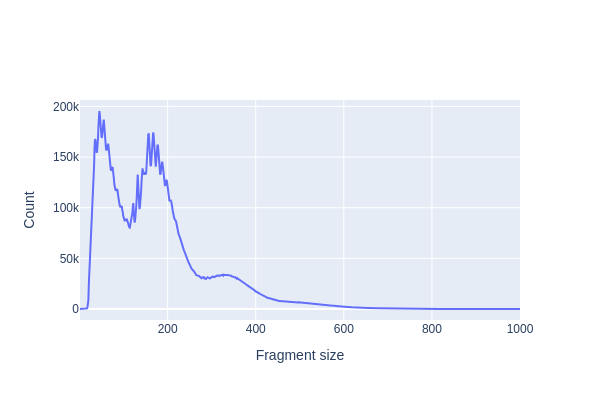

In [3]:
## Bit of extra information:
'''
1. Nucleosome-Free Region (NFR): The majority of fragments are short, typically around 80-300 base pairs (bp) in length. 
These short fragments represent regions of open chromatin where DNA is relatively accessible and not bound to nucleosomes. 
These regions are often referred to as nucleosome-free regions (NFRs) and correspond to regions of active transcriptional 
regulation.

2. Mono-Nucleosome Peaks: There is often a peak in the fragment size distribution at around 147-200 bp, 
which corresponds to the size of a single nucleosome wrapped DNA. These fragments result from the 
cutting of DNA by the transposase enzyme when it encounters a nucleosome, 
causing the DNA to be protected and resulting in fragments of the same size.

3. Di-Nucleosome Peaks: In addition to the mono-nucleosome peak, you may also observe 
a smaller peak at approximately 300-400 bp, corresponding to di-nucleosome fragments. 
These fragments occur when transposase cuts the DNA between two neighboring nucleosomes.

4. Large Fragments: Some larger fragments, greater than 500 bp in size, may be observed. 
These fragments can result from various sources, such as the presence of 
longer stretches of open chromatin or technical artifacts.
'''



snap.pl.frag_size_distr(data, interactive=False)

In [5]:
## Same plot with axis to log scale
fig = snap.pl.frag_size_distr(data, show=False)
fig.update_yaxes(type="log")
fig.show()

In [5]:
## TSS enrichment implies there is an increased accessibility or fragmentation of chromatin around the TSS
## Often indicative of promoter regions
snap.metrics.tsse(data, snap.genome.hg38)

2026-10-19 12:29:22 - INFO - Chromium init'ed with kwargs {}
2026-10-19 12:29:22 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-19 12:29:22 - INFO - Temp directory created: /tmp/tmp8ltcmdqg.
2026-10-19 12:29:22 - INFO - Opening browser.
2026-10-19 12:29:22 - INFO - Temp directory created: /tmp/tmpsl4ehyr4.
2026-10-19 12:29:22 - INFO - Temporary directory at: /tmp/tmpsl4ehyr4
2026-10-19 12:29:23 - INFO - Conforming 1 to file:///tmp/tmp8ltcmdqg/index.html
2026-10-19 12:29:23 - INFO - Waiting on all navigates
2026-10-19 12:29:25 - INFO - All navigates done, putting them all in queue.
2026-10-19 12:29:25 - INFO - Getting tab from queue (has 1)
2026-10-19 12:29:25 - INFO - Got 045E
2026-10-19 12:29:25 - INFO - Processing fig.png
2026-10-19 12:29:25 - INFO - Sending big command for fig.png.
2026-10-19 12:29:25 - INFO - Sent big command for fig.png.
2026-10-19 12:29:25 - INFO - 

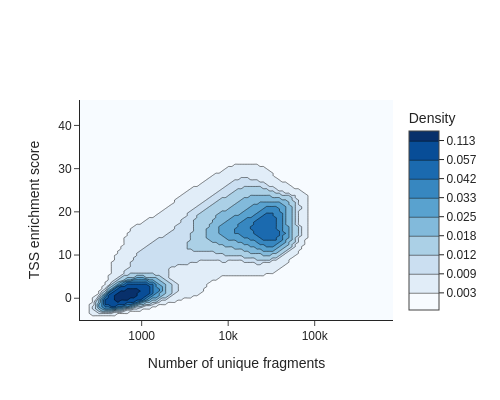

In [6]:
## To identify usable/high-quality cells, we can plot TSSe scores against number of unique fragments for each cell.
snap.pl.tsse(data, interactive=False)


##The cells in the upper right represent valid or high-quality cells, whereas those in the lower left represent low-quality 
# cells or empty droplets. Based on this plot, 
#we decided to set a minimum TSS enrichment of 10 and a minimum number of fragments of 5,000 to filter the cells.

In [7]:
## Oprion - Filtering cells here results in fewer mitochondrial variants deteced
snap.pp.filter_cells(data, min_counts=2000, min_tsse=4, max_counts=100000)
data

/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData object with n_obs × n_vars = 10645 × 0
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'Sample', 'Tissue', 'tsse'
    uns: 'reference_sequences', 'library_tsse', 'frac_overlap_TSS', 'TSS_profile'
    obsm: 'fragment_paired'

In [8]:
## Cell by bin matrix containng insertion counts across 500bp bins across the genome
snap.pp.add_tile_matrix(data)

In [9]:
## Feature selection, which will be stored in data.var['selected'] this is particularly relevant for scrublet and spectral
## Selects most accessible features 
## n_features determines number of features, experiment with n_features to find the optimal number for your dataset
snap.pp.select_features(data, n_features=150000)

2026-10-19 12:31:01 - INFO - Selected 150000 features.


In [10]:
%%time
snap.pp.scrublet(data)
snap.pp.filter_doublets(data)
data

2026-10-19 12:31:04 - INFO - Simulating doublets...
2026-10-19 12:31:06 - INFO - Spectral embedding ...
2026-10-19 12:31:07 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-19 12:31:07 - INFO - shutil.rmtree worked.
2026-10-19 12:33:20 - INFO - Calculating doublet scores...
2026-10-19 12:33:44 - INFO - Detected doublet rate = 2.527%


CPU times: user 22min 16s, sys: 9.66 s, total: 22min 26s
Wall time: 2min 48s


AnnData object with n_obs × n_vars = 10376 × 6062095
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'Sample', 'Tissue', 'tsse', 'doublet_probability', 'doublet_score'
    var: 'count', 'selected'
    uns: 'reference_sequences', 'library_tsse', 'frac_overlap_TSS', 'TSS_profile', 'scrublet_sim_doublet_score', 'doublet_rate'
    obsm: 'fragment_paired'

/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
2026-10-19 12:35:46 - INFO - Chromium init'ed with kwargs {}
2026-10-19 12:35:46 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-19 12:35:46 - INFO - Temp directory created: /tmp/tmp1qx19k3e.
2026-10-19 12:35:46 - INFO - Opening browser.
2026-10-19 12:35:46 - INFO - Temp directory created: /tmp/tmppwp0hss2.
2026-10-19 12:35:46 - INFO - Temporary directory at: /tmp/tmppwp0hss2
2026-10-19 12:35:47 - INFO - Conforming 1 to file:///tmp/tmp1qx19k3e/index.html
2026-10-19 12:35:47 - INFO - Waiting on all navigates
2026-10-19 12:35:49 - INFO - All navigates done, putting them all in queue.
2026-10-19 12:35:49 - INFO - Getting tab from queue (has 1)
2026-10-19 12:35:49 - INFO - Got E563

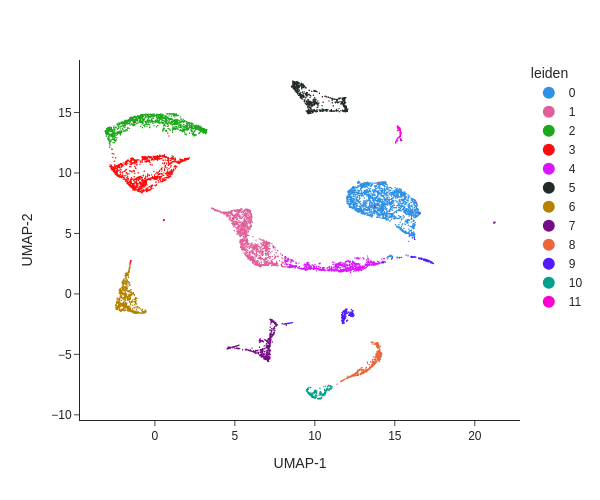

In [11]:
snap.tl.spectral(data)
snap.tl.umap(data) 
snap.pp.knn(data)
snap.tl.leiden(data, resolution=0.5)

snap.pl.umap(data, color='leiden', interactive=False, height=500)

2026-10-19 12:39:47 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-19 12:39:47 - INFO - shutil.rmtree worked.
2026-10-19 12:39:47 - INFO - Chromium init'ed with kwargs {}
2026-10-19 12:39:47 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-19 12:39:47 - INFO - Temp directory created: /tmp/tmppdqsonxy.
2026-10-19 12:39:47 - INFO - Opening browser.
2026-10-19 12:39:47 - INFO - Temp directory created: /tmp/tmpk2ns181_.
2026-10-19 12:39:47 - INFO - Temporary directory at: /tmp/tmpk2ns181_
2026-10-19 12:39:47 - INFO - Conforming 1 to file:///tmp/tmppdqsonxy/index.html
2026-10-19 12:39:47 - INFO - Waiting on all navigates
2026-10-19 12:39:49 - INFO - All navigates done, putting them all in queue.
2026-10-19 12:39:49 - INFO - Getting tab from queue (has 1)
2026-10-19 12:39:49 - INFO - Got DCC5
2026-10-19 12:39:49 - INFO - Processing fig.png
2026-10-19 12:39:49 - INFO - Send

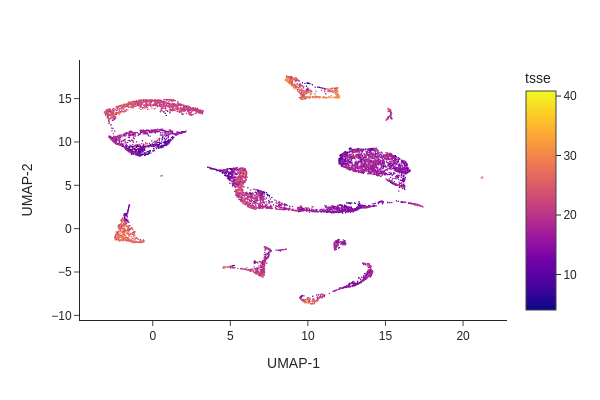

In [14]:
snap.pl.umap(data, color="tsse", interactive=False)


2026-10-19 13:10:04 - INFO - Chromium init'ed with kwargs {}
2026-10-19 13:10:04 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-19 13:10:04 - INFO - Temp directory created: /tmp/tmpqyf25lli.
2026-10-19 13:10:04 - INFO - Opening browser.
2026-10-19 13:10:04 - INFO - Temp directory created: /tmp/tmprwecmhot.


Sample                    BM  Brain
mtDNA_group                        
Microglia                 11   2630
Bone marrow cells       6659    394
non-immune brain cells     0    682


2026-10-19 13:10:05 - INFO - Temporary directory at: /tmp/tmprwecmhot
2026-10-19 13:10:05 - INFO - Conforming 1 to file:///tmp/tmpqyf25lli/index.html
2026-10-19 13:10:05 - INFO - Waiting on all navigates
2026-10-19 13:10:07 - INFO - All navigates done, putting them all in queue.
2026-10-19 13:10:07 - INFO - Getting tab from queue (has 1)
2026-10-19 13:10:07 - INFO - Got C6DB
2026-10-19 13:10:07 - INFO - Processing fig.png
2026-10-19 13:10:07 - INFO - Sending big command for fig.png.
2026-10-19 13:10:08 - INFO - Sent big command for fig.png.
2026-10-19 13:10:08 - INFO - Reloading tab C6DB before return.
2026-10-19 13:10:08 - INFO - Putting tab C6DB back (queue size: 0).
2026-10-19 13:10:08 - INFO - Waiting for all cleanups to finish.
2026-10-19 13:10:08 - INFO - Exiting Kaleido
2026-10-19 13:10:08 - INFO - Closing browser.
2026-10-19 13:10:08 - INFO - Closing browser.
2026-10-19 13:10:08 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-19 13:10:08 - INFO - shutil.rmtree worked.
202

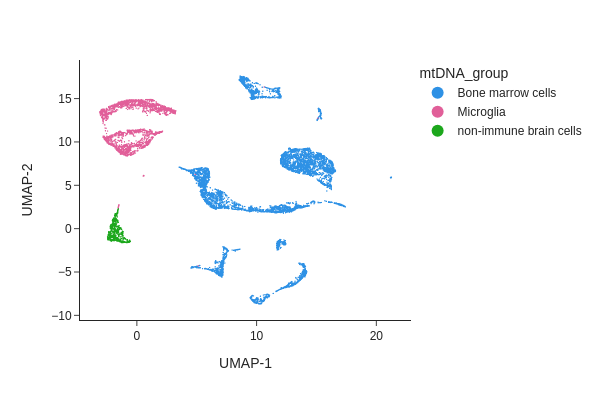

In [25]:
import pandas as pd

group_map = {
    "0":  "Bone marrow cells",
    "1":  "Bone marrow cells",
    "2":  "Microglia",
    "3":  "Microglia",
    "4":  "Bone marrow cells",
    "5":  "Bone marrow cells",  # T cells from either tissue
    "6":  "non-immune brain cells",
    "7":  "Bone marrow cells",
    "8":  "Bone marrow cells",
    "9":  "Bone marrow cells",
    "10": "Bone marrow cells",
    "11": "Bone marrow cells",
}

clusters = data.obs["leiden"].astype(str)
assert clusters.isin(group_map).all(), "Unmapped Leiden clusters present"

data.obs["mtDNA_group"] = pd.Categorical(
    clusters.map(group_map),
    categories=[
        "Microglia",
        "Bone marrow cells",
        "non-immune brain cells",
    ],
)

print(pd.crosstab(data.obs["mtDNA_group"], data.obs["Sample"]))

snap.pl.umap(data, color="mtDNA_group", interactive=False)

2026-10-05 17:04:24 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-05 17:04:24 - INFO - shutil.rmtree worked.


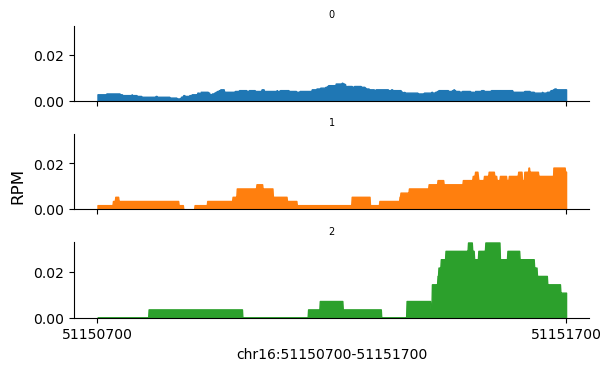

In [103]:
#Visualise accesibility of promoter regions of marker genes
snap.pl.coverage(data, region='chr16:51150700-51151700', groupby='leiden')


In [68]:
## Annotate the clusters and assign them to known cell types
## Compute gene activities for each cell using pp.make_gene_matrix

gene_matrix = snap.pp.make_gene_matrix(data, snap.genome.hg38)
gene_matrix

AnnData object with n_obs × n_vars = 1082 × 60606
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'tsse', 'doublet_probability', 'doublet_score', 'leiden', 'cell_type'

In [69]:
### The cell by gene activity matrix is sparse
## The MAGIC algorithm performs imputation and data smoothing
## Then scanpy does subsequent steps 
## First perform gene filtering, normalisation and transformation and then call MAGIC
sc.pp.filter_genes(gene_matrix, min_cells= 5)
sc.pp.normalize_total(gene_matrix)
sc.pp.log1p(gene_matrix)
# Skip MAGIC imputation - the analysis will work fine without it
sc.external.pp.magic(gene_matrix, solver="approximate")

# Copy over UMAP embedding
gene_matrix.obsm["X_umap"] = data.obsm["X_umap"]

2026-10-06 11:34:41 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-06 11:34:41 - INFO - shutil.rmtree worked.


... storing 'leiden' as categorical


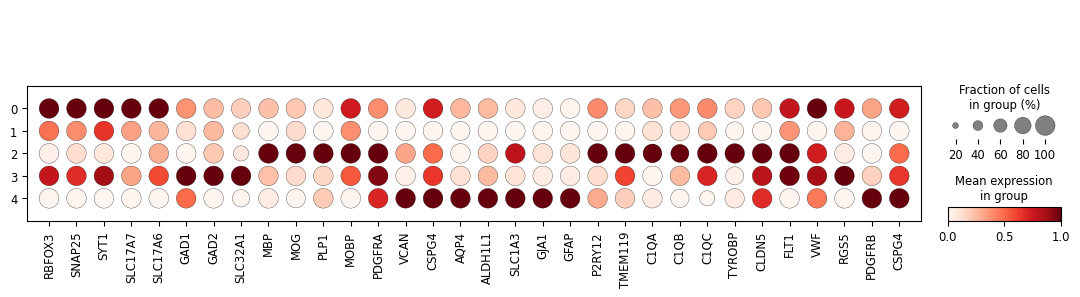

In [70]:
markers = [
    # Neurons
    "RBFOX3", "SNAP25", "SYT1",
    "SLC17A7", "SLC17A6",        # excitatory
    "GAD1", "GAD2", "SLC32A1",   # inhibitory

    # Oligodendrocytes / OPCs
    "MBP", "MOG", "PLP1", "MOBP",
    "PDGFRA", "VCAN", "CSPG4",

    # Astrocytes
    "AQP4", "ALDH1L1", "SLC1A3", "GJA1", "GFAP",

    # Microglia
    "P2RY12", "TMEM119", "C1QA", "C1QB", "C1QC", "TYROBP",

    # Vasculature
    "CLDN5", "FLT1", "VWF",      # endothelial
    "RGS5", "PDGFRB", "CSPG4"    # pericyte / mural
]

markers = [g for g in markers if g in gene_matrix.var_names]

sc.pl.dotplot(
    gene_matrix,
    var_names=markers,
    groupby="leiden",
    use_raw=False,
    standard_scale="var"
)

2026-10-05 17:11:31 - INFO - Chromium init'ed with kwargs {}
2026-10-05 17:11:31 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-05 17:11:31 - INFO - Temp directory created: /tmp/tmpnvav4e_r.
2026-10-05 17:11:31 - INFO - Opening browser.
2026-10-05 17:11:31 - INFO - Temp directory created: /tmp/tmplxzjh3__.
2026-10-05 17:11:31 - INFO - Temporary directory at: /tmp/tmplxzjh3__
2026-10-05 17:11:32 - INFO - Conforming 1 to file:///tmp/tmpnvav4e_r/index.html
2026-10-05 17:11:32 - INFO - Waiting on all navigates
2026-10-05 17:11:34 - INFO - All navigates done, putting them all in queue.
2026-10-05 17:11:34 - INFO - Getting tab from queue (has 1)
2026-10-05 17:11:34 - INFO - Got 3BB0
2026-10-05 17:11:34 - INFO - Processing fig.png
2026-10-05 17:11:34 - INFO - Sending big command for fig.png.
2026-10-05 17:11:35 - INFO - Sent big command for fig.png.
2026-10-05 17:11:35 - INFO - 

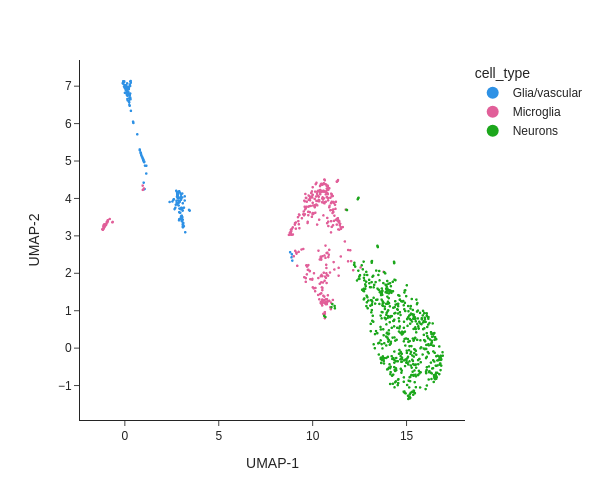

In [111]:
snap.pl.umap(
    data,
    color="cell_type",
    interactive=False,
    height=500
)

In [ ]:
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!    mtDNA VARIANT CALLING !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

Plotted variants: T-10410-C, A-2633-G, G-11711-A, G-1199-A, G-15927-A, A-4435-G, A-15924-G


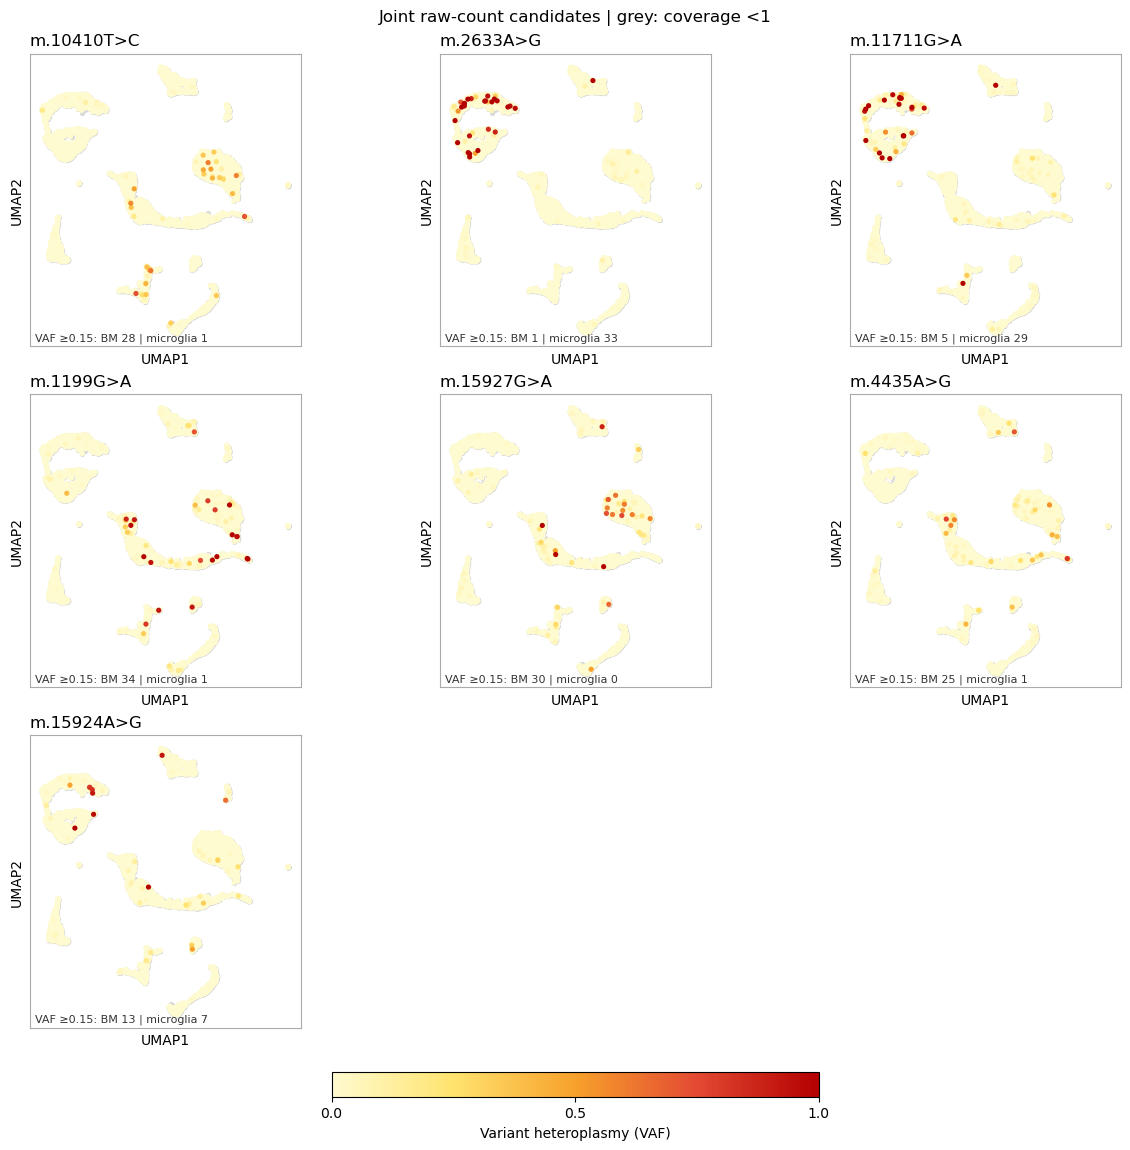

In [109]:
plot_joint_candidates_umap(
    mgatk_joint_raw,
    umap_source=data,
    variants=[
        "T-10410-C",
        "A-2633-G",
        "G-11711-A",
        "G-1199-A",
        "G-15927-A",
        "A-4435-G",
        "A-15924-G",
    ],
    min_depth=1,
    point_size=14,
)